# Experiment 3 — Linear, Ridge, and Lasso Regression

**Aim:** Fit and compare ordinary least-squares, Ridge, and Lasso regression for a continuous target.

**Libraries:** pandas, NumPy, Matplotlib, and scikit-learn.

**Theory:** Ridge adds an L2 coefficient penalty; Lasso adds an L1 penalty that can set coefficients to zero. Scaling and train-only preprocessing are important for valid comparison.

**Dataset:** California Housing dataset built into scikit-learn (`sklearn.datasets.fetch_california_housing()`, 20,640 districts, 8 features; target = median house value in units of $100,000). This is the dataset the manual specifies; a local CSV copy also exists in `datasets/` but is not needed here.

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

for candidate in [Path("outputs"), Path("../outputs")]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

RES_DIR = OUTPUT_DIR / "results"
FIG_DIR = OUTPUT_DIR / "figures"
RES_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the dataset

In [2]:
housing = fetch_california_housing()
X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name="MedHouseVal")

print("Feature matrix shape:", X.shape)
print("Features:", housing.feature_names)
print("Target: median house value in $100,000s")
X.head()

Feature matrix shape: (20640, 8)
Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: median house value in $100,000s


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


## 2. Train/test split (80:20) and feature scaling

The split uses `random_state=42` for reproducibility. A `StandardScaler` is **fit on the training set only**, then applied to both sets, so test data never leaks into training. Scaling puts all features on the same scale, which the regularised models (Ridge/Lasso) need so that the penalty treats every coefficient fairly.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}")

Train size: 16512 | Test size: 4128


## 3. Train LinearRegression, Ridge and Lasso (alpha = 1) and compare MSE / R²

In [4]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1)": Ridge(alpha=1, random_state=RANDOM_STATE),
    "Lasso (alpha=1)": Lasso(alpha=1, random_state=RANDOM_STATE, max_iter=10000),
}

rows = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    rows.append({
        "Model": name,
        "Test MSE": mean_squared_error(y_test, y_pred),
        "Test R2": r2_score(y_test, y_pred),
    })

comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
comparison.to_csv(RES_DIR / "exp03_model_comparison.csv", index=False)

            Model  Test MSE  Test R2
Linear Regression    0.5559   0.5758
  Ridge (alpha=1)    0.5559   0.5758
  Lasso (alpha=1)    1.3107  -0.0002


## 4. Effect of the regularisation strength `alpha`

Ridge and Lasso are re-trained for `alpha` ∈ {0.01, 0.1, 1, 10}. Test MSE/R² are recorded, and the coefficient of each feature is tracked to show how stronger penalties shrink the coefficients (Lasso can zero them out completely).

In [5]:
alphas = [0.01, 0.1, 1, 10]
coef_records = []
metric_records = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha, random_state=RANDOM_STATE).fit(X_train_scaled, y_train)
    lasso = Lasso(alpha=alpha, random_state=RANDOM_STATE, max_iter=10000).fit(X_train_scaled, y_train)
    for name, model in [("Ridge", ridge), ("Lasso", lasso)]:
        y_pred = model.predict(X_test_scaled)
        metric_records.append({
            "Model": name,
            "alpha": alpha,
            "Test MSE": mean_squared_error(y_test, y_pred),
            "Test R2": r2_score(y_test, y_pred),
            "Non-zero coefs": int((model.coef_ != 0).sum()),
        })
        for feat, coef in zip(housing.feature_names, model.coef_):
            coef_records.append({"Model": name, "alpha": alpha, "Feature": feat, "Coefficient": coef})

sweep = pd.DataFrame(metric_records)
print("Test metrics across alpha values:")
print(sweep.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
sweep.to_csv(RES_DIR / "exp03_alpha_sweep.csv", index=False)

Test metrics across alpha values:
Model   alpha  Test MSE  Test R2  Non-zero coefs
Ridge  0.0100    0.5559   0.5758               8
Lasso  0.0100    0.5483   0.5816               7
Ridge  0.1000    0.5559   0.5758               8
Lasso  0.1000    0.6796   0.4814               3
Ridge  1.0000    0.5559   0.5758               8
Lasso  1.0000    1.3107  -0.0002               0
Ridge 10.0000    0.5555   0.5761               8
Lasso 10.0000    1.3107  -0.0002               0



Ridge coefficients by alpha:
Feature  AveBedrms  AveOccup  AveRooms  HouseAge  Latitude  Longitude  MedInc  Population
alpha                                                                                    
0.01         0.339    -0.041    -0.294     0.123    -0.897     -0.870   0.854      -0.002
0.10         0.339    -0.041    -0.294     0.123    -0.897     -0.870   0.854      -0.002
1.00         0.339    -0.041    -0.294     0.123    -0.896     -0.869   0.854      -0.002
10.00        0.337    -0.041    -0.292     0.123    -0.889     -0.862   0.854      -0.002

Lasso coefficients by alpha:
Feature  AveBedrms  AveOccup  AveRooms  HouseAge  Latitude  Longitude  MedInc  Population
alpha                                                                                    
0.01         0.206    -0.031    -0.163     0.127    -0.790     -0.756   0.801        -0.0
0.10         0.000    -0.000    -0.000     0.106    -0.011     -0.000   0.711        -0.0
1.00         0.000     0.000     0.000  

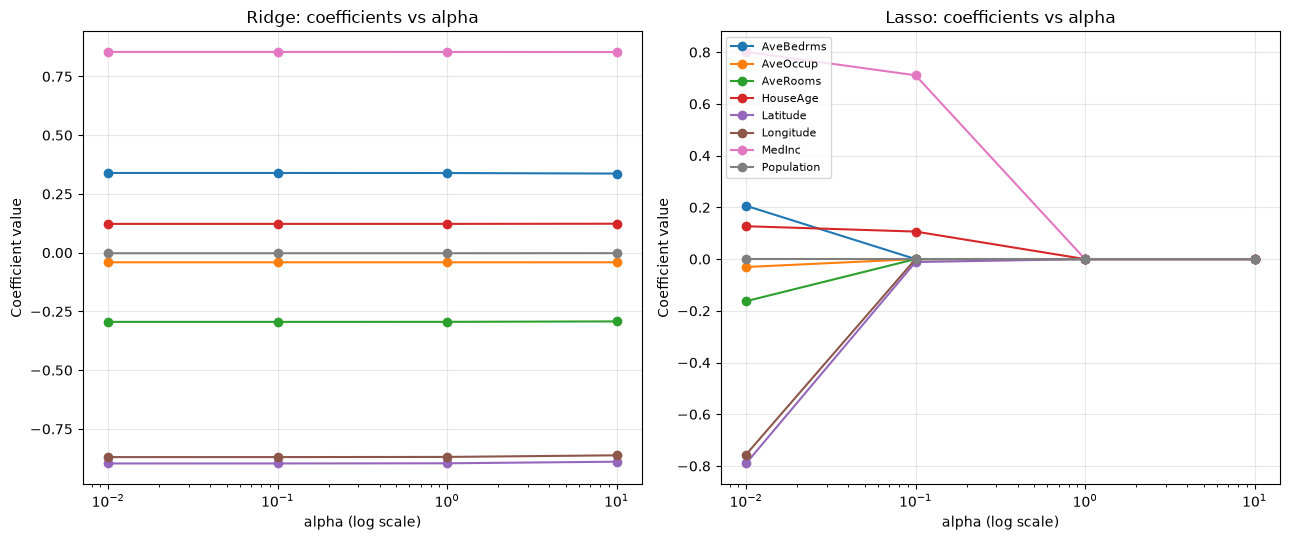

In [6]:
coef_df = pd.DataFrame(coef_records)
pivot_tables = {}
for name in ["Ridge", "Lasso"]:
    pivot = coef_df[coef_df["Model"] == name].pivot(index="alpha", columns="Feature", values="Coefficient")
    pivot_tables[name] = pivot
    print(f"\n{name} coefficients by alpha:")
    print(pivot.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, ["Ridge", "Lasso"]):
    pivot = pivot_tables[name]
    for feat in pivot.columns:
        ax.plot(pivot.index, pivot[feat], marker="o", label=feat)
    ax.set_xscale("log")
    ax.set_xlabel("alpha (log scale)")
    ax.set_ylabel("Coefficient value")
    ax.set_title(f"{name}: coefficients vs alpha")
    ax.grid(alpha=0.3)
axes[1].legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.savefig(FIG_DIR / "exp03_coefficients_vs_alpha.png", dpi=150)
plt.show()

## 5. Combined comparison table

All headline results (the three main models plus the full alpha sweep) in one place:

In [7]:
final = pd.concat([
    comparison.assign(alpha="(default 1)"),
    sweep.assign(alpha=sweep["alpha"].astype(str)),
], ignore_index=True, sort=False)
print(final.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

            Model  Test MSE  Test R2       alpha  Non-zero coefs
Linear Regression    0.5559   0.5758 (default 1)             NaN
  Ridge (alpha=1)    0.5559   0.5758 (default 1)             NaN
  Lasso (alpha=1)    1.3107  -0.0002 (default 1)             NaN
            Ridge    0.5559   0.5758        0.01          8.0000
            Lasso    0.5483   0.5816        0.01          7.0000
            Ridge    0.5559   0.5758         0.1          8.0000
            Lasso    0.6796   0.4814         0.1          3.0000
            Ridge    0.5559   0.5758         1.0          8.0000
            Lasso    1.3107  -0.0002         1.0          0.0000
            Ridge    0.5555   0.5761        10.0          8.0000
            Lasso    1.3107  -0.0002        10.0          0.0000


## Observation

Based on the run above:

1. Ordinary linear regression reaches **test MSE 0.556 and R² 0.576** — house prices depend on many factors beyond these 8 district features, so ~58% explained variance is the expected level for this dataset.
2. **Ridge barely changes anything** (MSE 0.556–0.559 for every alpha from 0.01 to 10): with only 8 moderately scaled features there is little overfitting for the L2 penalty to correct. The dominant coefficients are `MedInc` (+0.85), `Latitude` (−0.90) and `Longitude` (−0.87) — income and coastal location drive prices.
3. **Lasso is far more sensitive to alpha**: at `alpha=0.01` it keeps 7 of 8 features and even *slightly beats* ordinary regression (**R² 0.582 vs 0.576**); at `alpha=0.1` only 3 features survive (MedInc, HouseAge, a trace of Latitude) and R² drops to 0.481; at `alpha ≥ 1` **every coefficient is driven to exactly zero** and the model predicts only the mean (R² ≈ 0).
4. Conclusion: Ridge is the safe default when collinearity/overfitting is mild, while Lasso genuinely performs feature selection — but its alpha must be tuned carefully, because too large a penalty destroys the model. Both were trained on standardized features fit on the training split only.

## Result

The executed cells above provide the measured result for this experiment. The conclusion should be interpreted using the dataset and evaluation limits stated here.